# 02 — Backtest: baselines e modelos clássicos

**Pergunta do projeto:** dá para prever o IPCA de 1, 3 e 6 meses à frente com erro menor do que um modelo ingênuo,
e Selic e câmbio ajudam?

Este notebook define o esquema de validação e mede três baselines e três modelos clássicos:

| Modelo | Ideia |
|---|---|
| Ingênuo | repete o último IPCA |
| Ingênuo sazonal | repete o IPCA do mesmo mês do ano anterior |
| Média histórica | média de todo o histórico de treino |
| ETS(A,N,A) | suavização exponencial com sazonalidade aditiva, sem tendência |
| SARIMA(1,0,0)(1,0,0)₁₂ | AR(1) + AR sazonal, como sugerem a ACF/PACF da EDA |
| SARIMAX | o mesmo SARIMA com Selic e câmbio como regressores |

O código dos modelos está em `src/modelos.py`, o do backtest em `src/avaliacao.py` e as transformações em
`src/features.py` — o notebook 03 usa as mesmas peças.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.avaliacao import (HORIZONTE_MAX, HORIZONTES, INICIO_TREINO, PRIMEIRA_ORIGEM,
                           comparar_com, metricas, rodar_modelos)
from src.coleta import carregar_series
from src.features import DEFASAGEM_MACRO, macro_defasadas
from src.modelos import BASELINES, CLASSICOS, sarima

FIGURAS = RAIZ / "reports" / "figures"
PROCESSADOS = RAIZ / "data" / "processed"
PROCESSADOS.mkdir(parents=True, exist_ok=True)

# Cores por modelo (paleta categórica de referência, ordem fixa) + marcadores como segunda codificação.
CORES = {"Ingênuo": "#2a78d6", "Ingênuo sazonal": "#eb6834", "Média histórica": "#1baf7a",
         "ETS(A,N,A)": "#eda100", "SARIMA": "#e87ba4", "SARIMAX (Selic + câmbio)": "#008300"}
MARCADORES = {"Ingênuo": "o", "Ingênuo sazonal": "s", "Média histórica": "D",
              "ETS(A,N,A)": "^", "SARIMA": "v", "SARIMAX (Selic + câmbio)": "P"}
TEXTO, TEXTO_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRADE, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.titlecolor": TEXTO, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def salvar(fig, nome):
    fig.savefig(FIGURAS / f"{nome}.png")

df = carregar_series()
y = df["ipca"]
X = macro_defasadas(df)
X.loc["2026-01-01":].round(3)

,selic_dif_l6,cambio_var_l6
data,,
2026-01-01,0.18,-0.335
2026-02-01,-0.12,-1.476
2026-03-01,0.06,-1.460
2026-04-01,0.06,0.337
2026-05-01,-0.23,-0.828
2026-06-01,0.17,2.101
2026-07-01,-0.06,-2.111
2026-08-01,-0.16,-2.574
2026-09-01,0.21,0.596


## 1. Desenho do backtest

- **Janela expansiva.** Em cada mês de origem t, o modelo é treinado com todo o histórico até t e prevê t+1 a t+6.
  Na origem seguinte, o treino ganha um mês. Nada é embaralhado: o teste sempre vem depois do treino.
- **Origens:** de dez/2014 até o último mês com algum alvo conhecido. O teste começa em jan/2015 e atravessa anos
  calmos (2017–19) e a alta de 2020–23, que a EDA mostrou ter o dobro da volatilidade.
- **Treino a partir de jan/2004:** jan–mar/2003 ainda carregam o choque de 2002 (o maior IPCA mensal da amostra).
- **Sem vazamento.** Na data da previsão (logo após a divulgação do IPCA de t), Selic e câmbio só são conhecidos
  até t. Por isso entram no SARIMAX com **6 meses de defasagem**, o mínimo que torna legítima qualquer previsão até
  6 meses — o valor vem do horizonte, não da EDA, para não escolher defasagens olhando a amostra inteira. Selic em
  diferença mensal e câmbio em variação % mensal, as formas estacionárias da EDA. Um teste em `tests/test_vazamento.py` confirma: trocar
  todos os dados posteriores à origem por ruído não muda nenhuma previsão feita nela.
- **Métricas:** MAE e RMSE em pontos percentuais, por horizonte. O MAPE fica de fora: com o IPCA perto de zero
  (houve deflação em 16 meses), ele explode.

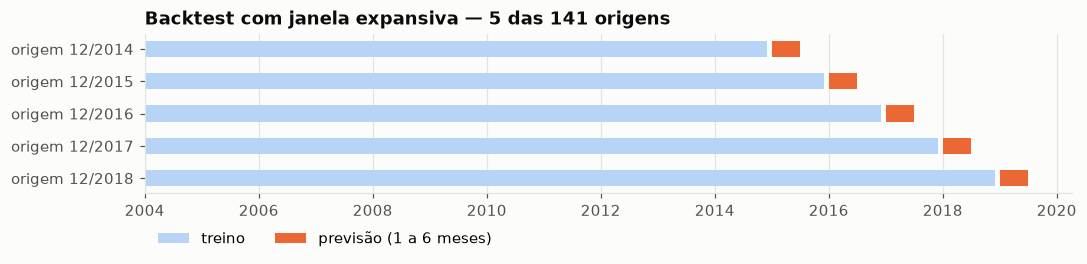

In [2]:
origens_exemplo = pd.date_range(PRIMEIRA_ORIGEM, periods=5, freq="12MS")
fig, eixo = plt.subplots(figsize=(10, 2.8))
inicio = pd.Timestamp(INICIO_TREINO)
for i, origem in enumerate(origens_exemplo):
    eixo.barh(i, origem - inicio, left=inicio, height=0.5, color="#b7d3f6", label="treino" if i == 0 else None)
    eixo.barh(i, pd.Timedelta(days=30.4 * HORIZONTE_MAX), left=origem + pd.DateOffset(months=1), height=0.5,
              color="#eb6834", label=f"previsão (1 a {HORIZONTE_MAX} meses)" if i == 0 else None)
eixo.set_yticks(range(len(origens_exemplo)), [f"origem {o:%m/%Y}" for o in origens_exemplo])
eixo.invert_yaxis()
eixo.grid(axis="y", visible=False)
eixo.set_title("Backtest com janela expansiva — 5 das 141 origens")
eixo.legend(frameon=False, loc="lower left", ncol=2, bbox_to_anchor=(0, -0.42))
fig.tight_layout()
salvar(fig, "07_backtest_janela_expansiva")
plt.show()

## 2. Rodando o backtest

In [3]:
modelos = {**BASELINES, **CLASSICOS}
inicio = time.perf_counter()
previsoes = rodar_modelos(y, modelos, X=X)
print(f"{len(modelos)} modelos, {previsoes['origem'].nunique()} origens "
      f"({previsoes['origem'].min():%m/%Y} a {previsoes['origem'].max():%m/%Y}), "
      f"{len(previsoes):,} previsões em {time.perf_counter() - inicio:.0f} s")

# Guardado para o notebook 03 (data/processed/ é refeito a partir de data/raw/).
previsoes.to_csv(PROCESSADOS / "backtest_classicos.csv", index=False, date_format="%Y-%m-%d")
previsoes.head()

6 modelos, 141 origens (12/2014 a 08/2026), 4,986 previsões em 100 s


,origem,alvo,h,previsto,real,modelo,erro
0,2014-12-01,2015-01-01,1,0.78,1.24,Ingênuo,-0.46
1,2014-12-01,2015-02-01,2,0.78,1.22,Ingênuo,-0.44
2,2014-12-01,2015-03-01,3,0.78,1.32,Ingênuo,-0.54
3,2014-12-01,2015-04-01,4,0.78,0.71,Ingênuo,0.07
4,2014-12-01,2015-05-01,5,0.78,0.74,Ingênuo,0.04


## 3. Erro por horizonte

In [4]:
tabela = metricas(previsoes).loc[(slice(None), list(HORIZONTES)), ["MAE", "RMSE"]]
tabela = tabela.unstack("h").round(3)
tabela.columns = [f"{m} h={h}" for m, h in tabela.columns]
tabela.loc[list(modelos)]

,MAE h=1,MAE h=3,MAE h=6,RMSE h=1,RMSE h=3,RMSE h=6
modelo,,,,,,
Ingênuo,0.293,0.389,0.411,0.391,0.499,0.559
Ingênuo sazonal,0.382,0.379,0.382,0.500,0.498,0.502
Média histórica,0.315,0.310,0.308,0.401,0.394,0.391
"ETS(A,N,A)",0.263,0.314,0.321,0.353,0.412,0.416
SARIMA,0.257,0.285,0.300,0.342,0.382,0.387
SARIMAX (Selic + câmbio),0.257,0.290,0.304,0.343,0.388,0.392


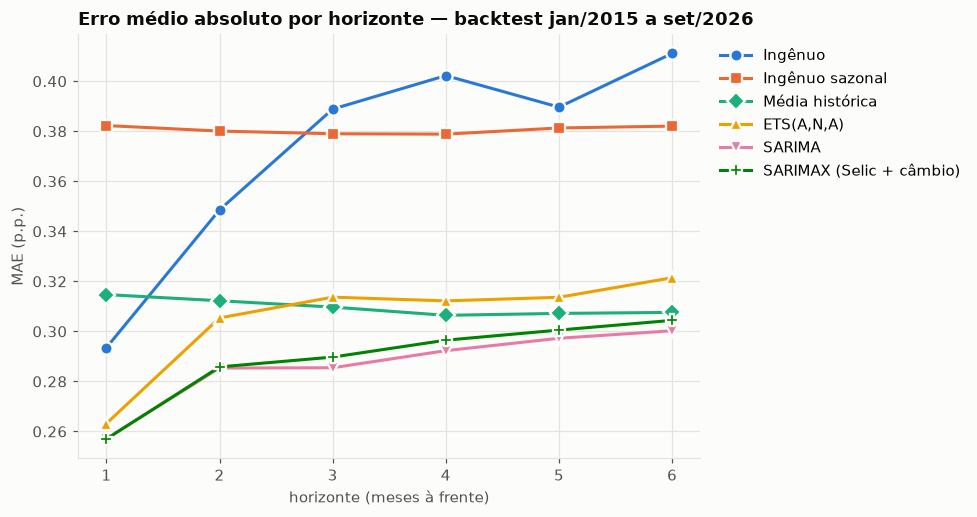

In [5]:
mae = metricas(previsoes)["MAE"].unstack("h")

fig, eixo = plt.subplots(figsize=(9, 4.8))
for nome in modelos:
    eixo.plot(mae.columns, mae.loc[nome], color=CORES[nome], marker=MARCADORES[nome], markersize=8,
              markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=nome)
eixo.set_xticks(range(1, HORIZONTE_MAX + 1))
eixo.set_xlabel("horizonte (meses à frente)")
eixo.set_ylabel("MAE (p.p.)")
eixo.set_title("Erro médio absoluto por horizonte — backtest jan/2015 a set/2026")
eixo.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
salvar(fig, "08_mae_por_horizonte")
plt.show()

## 4. Os modelos batem os baselines?

Comparo cada modelo com o **ingênuo** (o baseline da pergunta do projeto) e com o **melhor baseline em cada
horizonte**, que é o adversário mais honesto. O MAE relativo abaixo de 1 indica que o modelo erra menos. O teste de
**Diebold-Mariano** (com a correção de Harvey, Leybourne e Newbold para amostras pequenas) diz se a diferença de erro
é maior do que o acaso explicaria; p-valor < 0,05 = diferença significativa a 5%.

In [6]:
mae_baselines = mae.loc[list(BASELINES), list(HORIZONTES)]
melhor_baseline = mae_baselines.idxmin()
print("Melhor baseline por horizonte:", melhor_baseline.to_dict())

vs_ingenuo = comparar_com(previsoes, "Ingênuo")
partes = []
for h in HORIZONTES:
    ref = melhor_baseline[h]
    bloco = comparar_com(previsoes[previsoes["modelo"].isin([ref, *CLASSICOS])], ref, horizontes=[h])
    partes.append(bloco.assign(**{"melhor baseline": ref}))
vs_melhor = pd.concat(partes)

resumo = pd.concat({
    "vs. ingênuo": vs_ingenuo.loc[list(CLASSICOS)],
    "vs. melhor baseline": vs_melhor.loc[list(CLASSICOS)].drop(columns="melhor baseline"),
}, axis=1).round(3)
resumo

Melhor baseline por horizonte: {1: 'Ingênuo', 3: 'Média histórica', 6: 'Média histórica'}


vs. ingênuo            vs. melhor baseline  \
                           MAE relativo p-valor DM        MAE relativo   
modelo                   h                                               
ETS(A,N,A)               1        0.897      0.031               0.897   
                         3        0.807      0.000               1.013   
                         6        0.782      0.000               1.045   
SARIMA                   1        0.876      0.004               0.876   
                         3        0.734      0.000               0.922   
                         6        0.730      0.002               0.976   
SARIMAX (Selic + câmbio) 1        0.876      0.004               0.876   
                         3        0.745      0.000               0.935   
                         6        0.740      0.002               0.990   

                                       
                           p-valor DM  
modelo                   h             
ETS(A,N,A)               1      0.031  
                         3      0.864  
                         6      0.647  
SARIMA                   1      0.004  
                         3      0.024  
                         6      0.401  
SARIMAX (Selic + câmbio) 1      0.004  
                         3      0.081  
                         6      0.758

## 5. Selic e câmbio ajudam? (primeira ablação)

SARIMA e SARIMAX são o mesmo modelo, com e sem as variáveis macro: a diferença entre eles isola a contribuição de
Selic e câmbio. A ablação completa, com mais modelos, fica para o notebook 03.

In [7]:
ablacao = comparar_com(previsoes[previsoes["modelo"].isin(["SARIMA", "SARIMAX (Selic + câmbio)"])], "SARIMA")
ablacao = ablacao.rename(columns={"MAE relativo": "MAE SARIMAX / MAE SARIMA"}).round(3)
ablacao

MAE SARIMAX / MAE SARIMA  p-valor DM
modelo                   h                                      
SARIMAX (Selic + câmbio) 1                     1.000       0.963
                         3                     1.015       0.101
                         6                     1.014       0.070

## 6. Erro por período

A volatilidade do IPCA mudou muito no período de teste. O erro médio de toda a janela pode esconder que um modelo
vai bem nos anos calmos e mal nos agitados.

In [8]:
periodos = pd.cut(previsoes["alvo"].dt.year, [2014, 2019, 2023, 2030], labels=["2015–19", "2020–23", "2024–26"])
por_periodo = (previsoes.assign(periodo=periodos)
               .query("h in [1, 6]")
               .groupby(["h", "periodo", "modelo"], observed=True)["erro"]
               .apply(lambda e: e.abs().mean())
               .unstack("modelo")[list(modelos)]
               .round(3))
por_periodo

modelo     Ingênuo  Ingênuo sazonal  Média histórica  ETS(A,N,A)  SARIMA  \
h periodo                                                                  
1 2015–19    0.254            0.365            0.301       0.231   0.235   
  2020–23    0.330            0.508            0.380       0.324   0.296   
  2024–26    0.312            0.230            0.246       0.233   0.241   
6 2015–19    0.352            0.363            0.279       0.291   0.280   
  2020–23    0.522            0.508            0.383       0.415   0.372   
  2024–26    0.348            0.230            0.246       0.236   0.230   

modelo     SARIMAX (Selic + câmbio)  
h periodo                            
1 2015–19                     0.233  
  2020–23                     0.293  
  2024–26                     0.248  
6 2015–19                     0.283  
  2020–23                     0.378  
  2024–26                     0.233

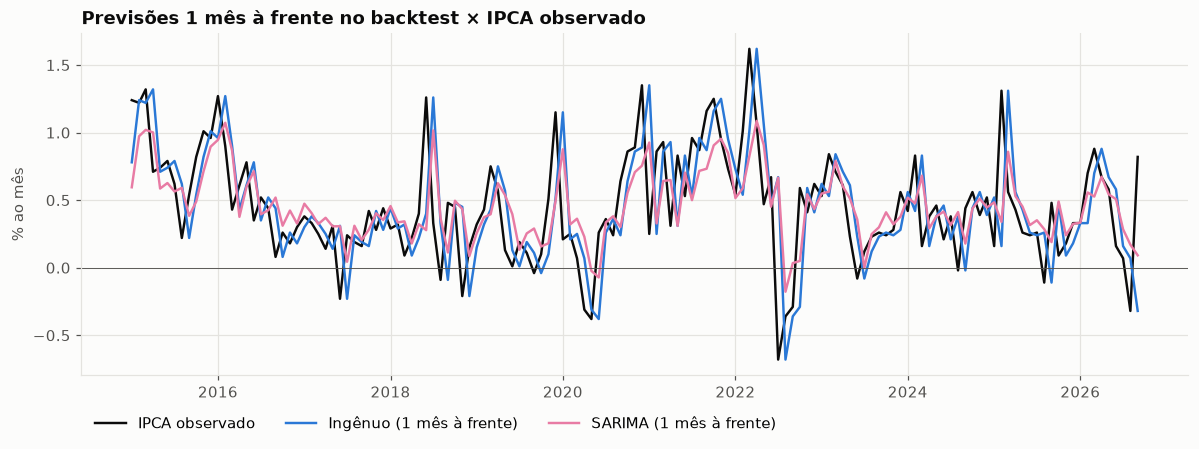

In [9]:
h1 = previsoes[previsoes["h"] == 1].pivot_table(index="alvo", columns="modelo", values="previsto")
real = y.loc[h1.index]

fig, eixo = plt.subplots(figsize=(11, 4.2))
eixo.plot(real.index, real, color=TEXTO, linewidth=1.6, label="IPCA observado")
for nome in ["Ingênuo", "SARIMA"]:
    eixo.plot(h1.index, h1[nome], color=CORES[nome], linewidth=1.6, label=f"{nome} (1 mês à frente)")
eixo.axhline(0, color=TEXTO_2, linewidth=0.6)
eixo.set_ylabel("% ao mês")
eixo.set_title("Previsões 1 mês à frente no backtest × IPCA observado")
eixo.legend(frameon=False, loc="upper left", ncol=3, bbox_to_anchor=(0, -0.08))
fig.tight_layout()
salvar(fig, "09_previsao_h1")
plt.show()

## 7. Previsão para os próximos 6 meses

Só para ilustrar: o SARIMA treinado com todos os dados até o último mês disponível, com intervalo de 80%. Não é um
resultado do projeto — o resultado é o erro no backtest acima.

In [10]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ajuste = SARIMAX(y.loc[INICIO_TREINO:], order=(1, 0, 0), seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False)
previsao = ajuste.get_forecast(HORIZONTE_MAX)
intervalo = previsao.conf_int(alpha=0.2)
proximos = pd.DataFrame({"previsão (%)": previsao.predicted_mean,
                         "limite inferior 80%": intervalo.iloc[:, 0],
                         "limite superior 80%": intervalo.iloc[:, 1]}).round(2)
proximos.index = proximos.index.strftime("%m/%Y")
acumulado = ((1 + previsao.predicted_mean / 100).prod() - 1) * 100
print(f"IPCA acumulado previsto em {HORIZONTE_MAX} meses: {acumulado:.2f}%")
proximos

IPCA acumulado previsto em 6 meses: 3.14%


,previsão (%),limite inferior 80%,limite superior 80%
10/2026,0.58,0.23,0.92
11/2026,0.50,0.11,0.90
12/2026,0.49,0.08,0.89
01/2027,0.46,0.05,0.87
02/2027,0.52,0.11,0.93
03/2027,0.55,0.14,0.96


## 8. Conclusões

**1. Dá para bater o modelo ingênuo — com folga e com significância.** O SARIMA erra 12% menos que repetir o último
IPCA em 1 mês (MAE de 0,257 contra 0,293 p.p.; Diebold-Mariano p = 0,004) e 27% menos em 3 e 6 meses (p < 0,01).
O ETS também bate o ingênuo em todos os horizontes.

**2. Mas o ingênuo é um adversário fraco além de 1 mês.** Em 3 e 6 meses, o melhor baseline é a **média histórica**,
e contra ela a vantagem encolhe: o SARIMA erra 8% menos em 3 meses (p = 0,024) e só 2% menos em 6 meses, diferença
que não é significativa (p = 0,40). O ETS não bate a média em 3 nem em 6 meses. Ou seja: **a 6 meses de distância, o
passado do IPCA já não diz muito mais do que a sua média** — coerente com a memória curta vista na ACF da EDA.

**3. Selic e câmbio não ajudaram no SARIMAX.** Com as duas variáveis (defasadas em 6 meses), o erro fica igual em
1 mês e 1,5% pior em 3 e 6 meses (diferenças não significativas). É um resultado para um modelo linear e uma única
defasagem; o notebook 03 testa de novo com o LightGBM, que pode usar várias defasagens e relações não lineares.

**4. O ingênuo sazonal, que parecia bom na EDA, vai mal no backtest** (MAE ≈ 0,38 p.p. em todos os horizontes). A
medida da EDA era na amostra inteira; aqui é fora da amostra e num período mais volátil. Bom lembrete de por que o
backtest é obrigatório.

**5. O erro depende muito do período.** Todos os modelos erram bem mais em 2020–23. O SARIMA foi o melhor justamente
nesses anos (0,296 p.p. em 1 mês e 0,372 em 6). Já em 2024–26, com a inflação mais estável, baselines simples
empatam com ele em 6 meses (ingênuo sazonal 0,230, SARIMA 0,230).

**Resposta parcial à pergunta do projeto:** sim para 1 e 3 meses, contra qualquer baseline; para 6 meses, os modelos
clássicos só batem o ingênuo, não a média histórica. E, até aqui, as variáveis macro não ajudam.

**Próximo passo (notebook 03):** LightGBM com defasagens do IPCA, da Selic e do câmbio, e Prophet, na mesma
estrutura de backtest, com a ablação completa com e sem as variáveis macro. As previsões deste notebook estão em
`data/processed/backtest_classicos.csv` para a comparação.
